<a href="https://colab.research.google.com/github/harishwork-s/Dl-test-73/blob/main/household_power_consumption_model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import os
import numpy as np
import pandas as pd

FILE_PATH = "/content/drive/MyDrive/DL dataset/household_power_consumption.csv"

if not os.path.exists(FILE_PATH):
    raise FileNotFoundError(f"Dataset not found: {FILE_PATH}")

df = pd.read_csv(
    FILE_PATH,
    sep=",",
    na_values=["?", ""],
    low_memory=False
)

df["Datetime"] = pd.to_datetime(
    df["Date"].astype(str) + " " + df["Time"].astype(str),
    format="%d/%m/%Y %H:%M:%S",
    errors="coerce"
)

features = [
    "Global_active_power",
    "Global_reactive_power",
    "Voltage",
    "Global_intensity",
    "Sub_metering_1",
    "Sub_metering_2"
]

for col in features + ["Sub_metering_3"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = (
    df.dropna(subset=["Datetime"])
      .sort_values("Datetime")
      .drop_duplicates("Datetime")
      .set_index("Datetime")
)

# First try to find 10,000 consecutive valid minute records.
minute_df = df[features].dropna()
minute_df = minute_df[
    minute_df.index.to_series().diff().eq(pd.Timedelta(minutes=1))
    | minute_df.index.to_series().diff().isna()
]

# Identify the longest continuous run without missing minutes.
groups = (
    minute_df.index.to_series()
    .diff()
    .ne(pd.Timedelta(minutes=1))
    .cumsum()
)

runs = [
    group for _, group in minute_df.groupby(groups)
    if len(group) >= 10000
]

if runs:
    data = runs[0].iloc[:10000].copy()
    interval = "minute"
    print("Using 10,000 consecutive valid minute records.")

else:
    print("No 10,000-minute valid run found. Using hourly data.")

    hourly = df[features].resample("h").mean()

    # Fill short gaps only; do not fabricate long missing periods.
    hourly = hourly.interpolate(
        method="time",
        limit=2,
        limit_area="inside"
    )

    hourly = hourly.dropna()

    hourly_groups = (
        hourly.index.to_series()
        .diff()
        .ne(pd.Timedelta(hours=1))
        .cumsum()
    )

    hourly_runs = [
        group for _, group in hourly.groupby(hourly_groups)
        if len(group) >= 10000
    ]

    if not hourly_runs:
        raise ValueError(
            "No suitable 10,000-record continuous window found. "
            "Inspect the dataset's missing values and date coverage."
        )

    data = hourly_runs[0].iloc[:10000].copy()
    interval = "hour"

print("Selected data shape:", data.shape)
print("Time interval:", interval)
print("Start:", data.index.min())
print("End:", data.index.max())
print("Remaining missing values:", data.isna().sum().sum())

display(data.head())


Using 10,000 consecutive valid minute records.
Selected data shape: (10000, 6)
Time interval: minute
Start: 2006-12-21 11:26:00
End: 2006-12-28 10:05:00
Remaining missing values: 0


,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2
Datetime,,,,,,
2006-12-21 11:26:00,0.246,0.0,241.83,1.0,0.0,0.0
2006-12-21 11:27:00,0.244,0.0,240.96,1.0,0.0,0.0
2006-12-21 11:28:00,0.244,0.0,241.37,1.0,0.0,0.0
2006-12-21 11:29:00,0.244,0.0,241.33,1.0,0.0,0.0
2006-12-21 11:30:00,0.244,0.0,241.76,1.0,0.0,0.0


In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

LOOKBACK = 60
TARGET = "Global_active_power"

print("Libraries imported successfully!")
print("Previous 60 minutes will predict the next minute.")

Libraries imported successfully!
Previous 60 minutes will predict the next minute.


In [5]:
values = data[features].astype("float32").values

split = int(len(values) * 0.80)

train_data = values[:split]
test_data = values[split:]

print("Total records:", len(values))
print("Training records:", len(train_data))
print("Testing records:", len(test_data))

Total records: 10000
Training records: 8000
Testing records: 2000


In [6]:
feature_scaler = MinMaxScaler()
target_scaler = MinMaxScaler()

feature_scaler.fit(train_data)

target_index = features.index(TARGET)
target_scaler.fit(train_data[:, [target_index]])

scaled_values = feature_scaler.transform(values)
scaled_target = target_scaler.transform(
    values[:, [target_index]]
)

print("Normalization completed!")
print("Scaled feature shape:", scaled_values.shape)

Normalization completed!
Scaled feature shape: (10000, 6)


In [7]:
X, y = [], []

for i in range(LOOKBACK, len(values)):
    X.append(scaled_values[i-LOOKBACK:i])
    y.append(scaled_target[i, 0])

X = np.array(X, dtype=np.float32)
y = np.array(y, dtype=np.float32)

# Keep the chronological order
X_train, y_train = X[:split-LOOKBACK], y[:split-LOOKBACK]
X_test, y_test = X[split-LOOKBACK:], y[split-LOOKBACK:]

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (7940, 60, 6)
y_train: (7940,)
X_test: (2000, 60, 6)
y_test: (2000,)


In [8]:
tf.keras.utils.set_random_seed(42)

model = Sequential([
    Input(shape=(LOOKBACK, len(features))),
    LSTM(64, return_sequences=True),
    Dropout(0.2),
    LSTM(32),
    Dropout(0.2),
    Dense(16, activation="relu"),
    Dense(1)
])

model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 60, 64)         │        18,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 60, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 31,137 (121.63 KB)

 Trainable params: 31,137 (121.63 KB)

 Non-trainable params: 0 (0.00 B)

In [9]:
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    epochs=30,
    batch_size=64,
    validation_split=0.15,
    shuffle=False,
    callbacks=[early_stop],
    verbose=1
)

print("Model training completed!")

Epoch 1/30
106/106 ━━━━━━━━━━━━━━━━━━━━ 7s 14ms/step - loss: 0.0177 - mae: 0.0997 - val_loss: 0.0076 - val_mae: 0.0671
Epoch 2/30
106/106 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0114 - mae: 0.0766 - val_loss: 0.0054 - val_mae: 0.0558
Epoch 3/30
106/106 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0096 - mae: 0.0698 - val_loss: 0.0043 - val_mae: 0.0473
Epoch 4/30
106/106 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0087 - mae: 0.0660 - val_loss: 0.0037 - val_mae: 0.0432
Epoch 5/30
106/106 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0079 - mae: 0.0620 - val_loss: 0.0036 - val_mae: 0.0428
Epoch 6/30
106/106 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0076 - mae: 0.0605 - val_loss: 0.0032 - val_mae: 0.0396
Epoch 7/30
106/106 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0073 - mae: 0.0589 - val_loss: 0.0029 - val_mae: 0.0365
Epoch 8/30
106/106 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0071 - mae: 0.0577 - val_loss: 0.0028 - val_mae: 0.0349
Epoch 9/30
106/106 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/

In [10]:
pred_scaled = model.predict(X_test, verbose=0)

actual = target_scaler.inverse_transform(
    y_test.reshape(-1, 1)
).ravel()

predicted = target_scaler.inverse_transform(
    pred_scaled
).ravel()

mae = mean_absolute_error(actual, predicted)
rmse = np.sqrt(mean_squared_error(actual, predicted))

print(f"MAE:  {mae:.4f} kW")
print(f"RMSE: {rmse:.4f} kW")

MAE:  0.1581 kW
RMSE: 0.2850 kW


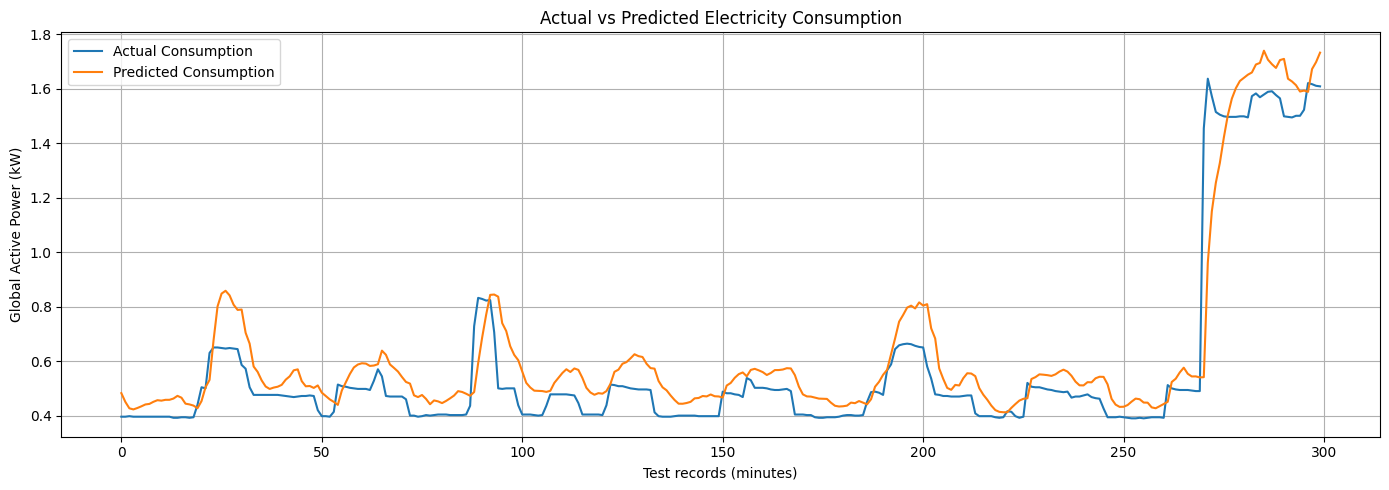

In [11]:
plt.figure(figsize=(14, 5))

plt.plot(actual[:300], label="Actual Consumption")
plt.plot(predicted[:300], label="Predicted Consumption")

plt.title("Actual vs Predicted Electricity Consumption")
plt.xlabel("Test records (minutes)")
plt.ylabel("Global Active Power (kW)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [12]:
import os
import json
import joblib

SAVE_DIR = "/content/drive/MyDrive/Electricity_LSTM_Model"
os.makedirs(SAVE_DIR, exist_ok=True)

model.save(f"{SAVE_DIR}/electricity_lstm.keras")

joblib.dump(
    feature_scaler,
    f"{SAVE_DIR}/feature_scaler.pkl"
)

joblib.dump(
    target_scaler,
    f"{SAVE_DIR}/target_scaler.pkl"
)

with open(f"{SAVE_DIR}/model_config.json", "w") as f:
    json.dump({
        "features": features,
        "target": TARGET,
        "lookback": LOOKBACK,
        "interval": "minute"
    }, f, indent=2)

print("Model and scalers saved successfully!")
print("Google Drive location:", SAVE_DIR)


Model and scalers saved successfully!
Google Drive location: /content/drive/MyDrive/Electricity_LSTM_Model


In [13]:
from google.colab import files
import pandas as pd

template = pd.DataFrame({
    col: [""] * 60 for col in features
})

template_path = "/content/electricity_input_template.csv"
template.to_csv(template_path, index=False)

print("CSV template created!")
print("Fill all 60 rows with real electricity readings.")

files.download(template_path)


CSV template created!
Fill all 60 rows with real electricity readings.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [15]:
# Create a filled input CSV using actual unseen measurements
sample_rows = data[features].iloc[split-60:split].copy()

sample_path = "/content/my_electricity_readings.csv"
sample_rows.to_csv(sample_path, index=False)

print("Filled sample CSV created:", sample_path)
display(sample_rows.head())

from google.colab import files
files.download(sample_path)


Filled sample CSV created: /content/my_electricity_readings.csv


,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2
Datetime,,,,,,
2006-12-26 23:46:00,0.422,0.000,246.99,2.0,0.0,0.0
2006-12-26 23:47:00,0.456,0.000,246.81,2.2,0.0,0.0
2006-12-26 23:48:00,0.508,0.136,247.07,2.4,0.0,0.0
2006-12-26 23:49:00,0.604,0.136,247.25,2.6,0.0,0.0
2006-12-26 23:50:00,0.606,0.138,247.33,2.6,0.0,0.0


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [16]:

from google.colab import files
import pandas as pd
import numpy as np
import tensorflow as tf
import joblib
import json
import os

SAVE_DIR = "/content/drive/MyDrive/Electricity_LSTM_Model"

# Load saved model and scalers
model = tf.keras.models.load_model(
    f"{SAVE_DIR}/electricity_lstm.keras"
)
feature_scaler = joblib.load(f"{SAVE_DIR}/feature_scaler.pkl")
target_scaler = joblib.load(f"{SAVE_DIR}/target_scaler.pkl")

with open(f"{SAVE_DIR}/model_config.json") as f:
    config = json.load(f)

features = config["features"]
LOOKBACK = config["lookback"]

# Upload the completed CSV
uploaded = files.upload()
filename = next(iter(uploaded))

input_df = pd.read_csv(filename)

# Validate input
if any(col not in input_df.columns for col in features):
    raise ValueError("The CSV does not contain all required columns.")

input_df = input_df[features].apply(pd.to_numeric, errors="coerce")

if input_df.shape != (LOOKBACK, len(features)):
    raise ValueError(f"Expected 60 rows and {len(features)} columns.")

if input_df.isna().any().any():
    raise ValueError("The uploaded CSV contains missing or invalid values.")

if not np.isfinite(input_df.to_numpy()).all():
    raise ValueError("The CSV contains infinite or invalid values.")

# Generate prediction
scaled_input = feature_scaler.transform(input_df.values)
X_input = scaled_input.reshape(1, LOOKBACK, len(features))

pred_scaled = model.predict(X_input, verbose=0)
prediction = target_scaler.inverse_transform(pred_scaled)[0, 0]
prediction = max(0.0, float(prediction))

print("\n===== ELECTRICITY FORECAST =====")
print(f"Predicted next-minute active power: {prediction:.4f} kW")
print(f"Equivalent power: {prediction * 1000:.1f} watts")
print("================================")


Saving my_electricity_readings.csv to my_electricity_readings (1).csv

===== ELECTRICITY FORECAST =====
Predicted next-minute active power: 0.4825 kW
Equivalent power: 482.5 watts


In [17]:

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# LSTM predictions on the held-out test period
pred_scaled = model.predict(X_test, verbose=0)

actual_kw = target_scaler.inverse_transform(
    y_test.reshape(-1, 1)
).ravel()

lstm_kw = target_scaler.inverse_transform(
    pred_scaled
).ravel()

# Persistence baseline: use the latest active-power measurement
active_power_index = features.index("Global_active_power")

latest_scaled = X_test[:, -1, active_power_index].reshape(-1, 1)

baseline_kw = target_scaler.inverse_transform(
    latest_scaled
).ravel()

def calculate_metrics(actual, prediction):
    return {
        "MAE (kW)": mean_absolute_error(actual, prediction),
        "RMSE (kW)": np.sqrt(mean_squared_error(actual, prediction))
    }

results = pd.DataFrame({
    "LSTM": calculate_metrics(actual_kw, lstm_kw),
    "Persistence Baseline": calculate_metrics(actual_kw, baseline_kw)
}).T

display(results.round(4))

,MAE (kW),RMSE (kW)
LSTM,0.1581,0.2850
Persistence Baseline,0.0601,0.2268


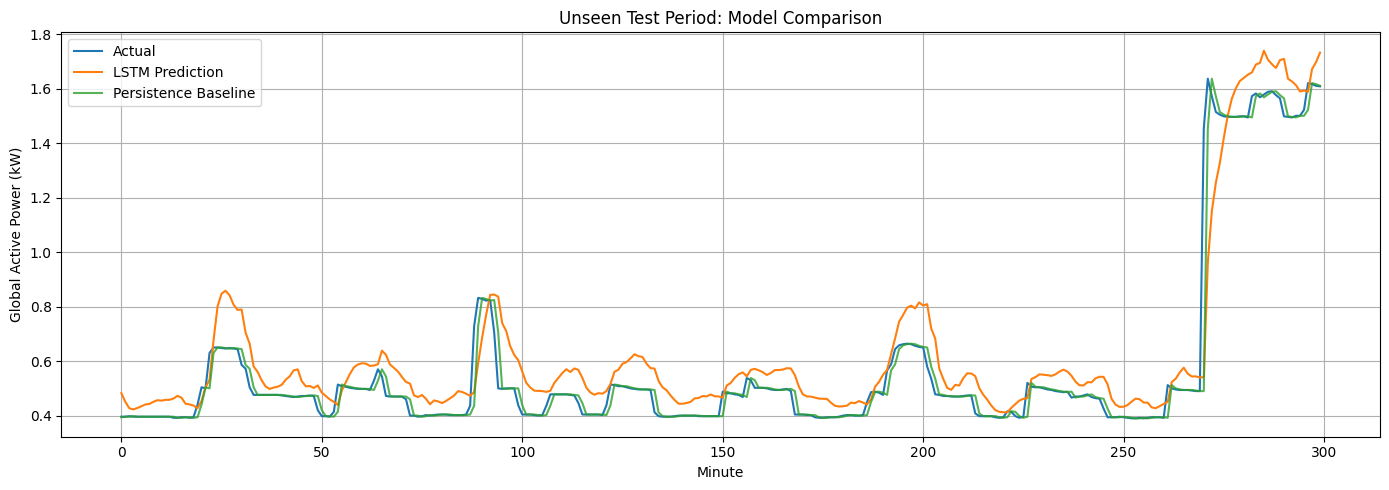

In [18]:

import matplotlib.pyplot as plt

N = min(300, len(actual_kw))

plt.figure(figsize=(14, 5))
plt.plot(actual_kw[:N], label="Actual")
plt.plot(lstm_kw[:N], label="LSTM Prediction")
plt.plot(baseline_kw[:N], label="Persistence Baseline", alpha=0.8)

plt.title("Unseen Test Period: Model Comparison")
plt.xlabel("Minute")
plt.ylabel("Global Active Power (kW)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [19]:
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
import numpy as np
import pandas as pd
import tensorflow as tf

tf.keras.utils.set_random_seed(42)

# Use only the target feature
power = data[["Global_active_power"]].values.astype("float32")

split = int(len(power) * 0.80)
LOOKBACK = 60

power_scaler = MinMaxScaler()
power_scaler.fit(power[:split])

power_scaled = power_scaler.transform(power)

X_power, y_power = [], []

for i in range(LOOKBACK, len(power)):
    X_power.append(power_scaled[i-LOOKBACK:i])
    y_power.append(power_scaled[i, 0])

X_power = np.array(X_power, dtype=np.float32)
y_power = np.array(y_power, dtype=np.float32)

X_train_new = X_power[:split-LOOKBACK]
y_train_new = y_power[:split-LOOKBACK]
X_test_new = X_power[split-LOOKBACK:]
y_test_new = y_power[split-LOOKBACK:]

improved_model = Sequential([
    Input(shape=(LOOKBACK, 1)),
    LSTM(32),
    Dropout(0.1),
    Dense(16, activation="relu"),
    Dense(1)
])

improved_model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

improved_model.fit(
    X_train_new,
    y_train_new,
    epochs=30,
    batch_size=64,
    validation_split=0.15,
    shuffle=False,
    callbacks=[
        EarlyStopping(
            monitor="val_loss",
            patience=5,
            restore_best_weights=True
        )
    ],
    verbose=1
)

print("Simplified LSTM training completed.")

Epoch 1/30
106/106 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - loss: 0.0110 - mae: 0.0721 - val_loss: 0.0033 - val_mae: 0.0352
Epoch 2/30
106/106 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - loss: 0.0072 - mae: 0.0560 - val_loss: 0.0030 - val_mae: 0.0340
Epoch 3/30
106/106 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0065 - mae: 0.0523 - val_loss: 0.0025 - val_mae: 0.0298
Epoch 4/30
106/106 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0063 - mae: 0.0504 - val_loss: 0.0021 - val_mae: 0.0245
Epoch 5/30
106/106 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0063 - mae: 0.0507 - val_loss: 0.0021 - val_mae: 0.0255
Epoch 6/30
106/106 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0062 - mae: 0.0495 - val_loss: 0.0019 - val_mae: 0.0235
Epoch 7/30
106/106 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0060 - mae: 0.0484 - val_loss: 0.0018 - val_mae: 0.0225
Epoch 8/30
106/106 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0059 - mae: 0.0489 - val_loss: 0.0017 - val_mae: 0.0212
Epoch 9/30
106/106 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - 

In [20]:
# Predictions from the simplified LSTM
simple_scaled = improved_model.predict(X_test_new, verbose=0)

simple_pred = power_scaler.inverse_transform(
    simple_scaled
).ravel()

simple_actual = power_scaler.inverse_transform(
    y_test_new.reshape(-1, 1)
).ravel()

# Persistence baseline for the same test timestamps
simple_baseline = power_scaler.inverse_transform(
    X_test_new[:, -1, :]
).ravel()

comparison = pd.DataFrame({
    "Previous LSTM": [
        mean_absolute_error(actual_kw, lstm_kw),
        np.sqrt(mean_squared_error(actual_kw, lstm_kw))
    ],
    "Simplified LSTM": [
        mean_absolute_error(simple_actual, simple_pred),
        np.sqrt(mean_squared_error(simple_actual, simple_pred))
    ],
    "Persistence Baseline": [
        mean_absolute_error(simple_actual, simple_baseline),
        np.sqrt(mean_squared_error(simple_actual, simple_baseline))
    ]
}, index=["MAE (kW)", "RMSE (kW)"]).T

display(comparison.round(4))


,MAE (kW),RMSE (kW)
Previous LSTM,0.1581,0.2850
Simplified LSTM,0.1490,0.2759
Persistence Baseline,0.0601,0.2268


In [21]:
import os
import json
import joblib

SAVE_DIR = "/content/drive/MyDrive/Electricity_LSTM_Model"
os.makedirs(SAVE_DIR, exist_ok=True)

# Save simplified LSTM separately
improved_model.save(
    f"{SAVE_DIR}/electricity_lstm_simplified.keras"
)

joblib.dump(
    power_scaler,
    f"{SAVE_DIR}/power_scaler_simplified.pkl"
)

# Save evaluation results
metrics = {
    "previous_lstm_mae_kw": 0.1581,
    "previous_lstm_rmse_kw": 0.2850,
    "simplified_lstm_mae_kw": 0.1490,
    "simplified_lstm_rmse_kw": 0.2759,
    "persistence_baseline_mae_kw": 0.0601,
    "persistence_baseline_rmse_kw": 0.2268,
    "lookback_minutes": LOOKBACK,
    "target": "Global_active_power"
}

with open(f"{SAVE_DIR}/evaluation_metrics.json", "w") as f:
    json.dump(metrics, f, indent=2)

print("Simplified model saved successfully!")
print("Location:", SAVE_DIR)

Simplified model saved successfully!
Location: /content/drive/MyDrive/Electricity_LSTM_Model


In [22]:

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# Use the same test timestamps for all models.
# Previous LSTM
old_pred = lstm_kw

# Simplified LSTM
simple_pred = simple_pred

# Persistence baseline
baseline_pred = simple_baseline

# Confirm that predictions correspond to the same actual targets.
assert len(old_pred) == len(simple_pred) == len(baseline_pred)
assert len(actual_kw) == len(simple_pred)

comparison = pd.DataFrame({
    "Model": [
        "Previous LSTM",
        "Simplified LSTM",
        "Persistence Baseline"
    ],
    "MAE (kW)": [
        mean_absolute_error(actual_kw, old_pred),
        mean_absolute_error(actual_kw, simple_pred),
        mean_absolute_error(actual_kw, baseline_pred)
    ],
    "RMSE (kW)": [
        np.sqrt(mean_squared_error(actual_kw, old_pred)),
        np.sqrt(mean_squared_error(actual_kw, simple_pred)),
        np.sqrt(mean_squared_error(actual_kw, baseline_pred))
    ]
})

display(comparison.round(4))


,Model,MAE (kW),RMSE (kW)
0,Previous LSTM,0.1581,0.2850
1,Simplified LSTM,0.1490,0.2759
2,Persistence Baseline,0.0601,0.2268


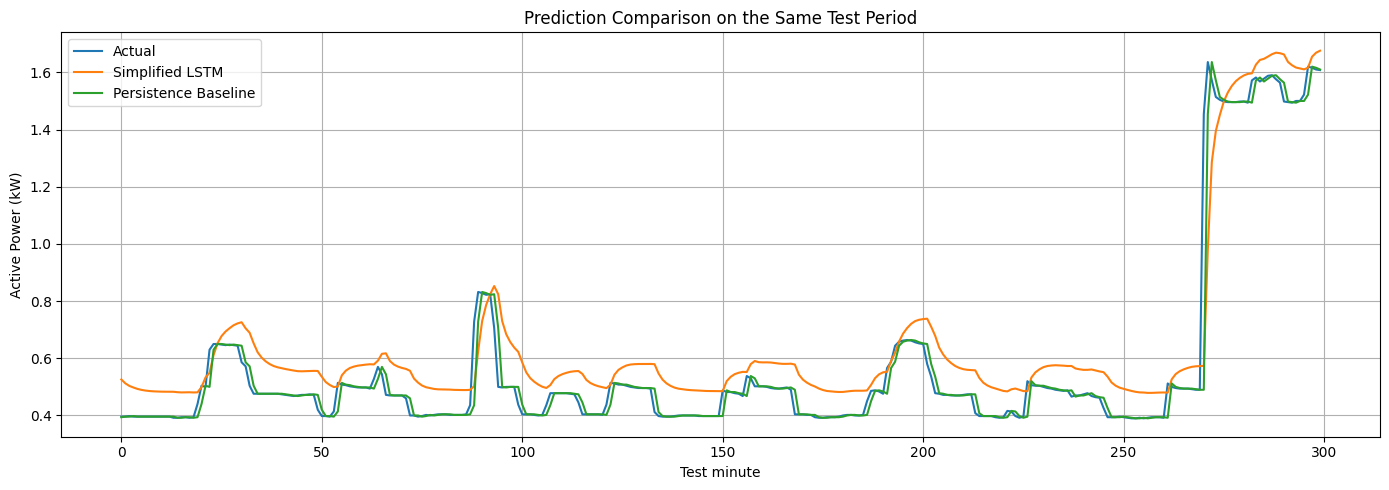

Largest LSTM errors:


,Actual (kW),Simplified LSTM (kW),Baseline (kW),LSTM Absolute Error,Baseline Absolute Error
383,5.560,1.8605,2.832,3.6995,2.728
1822,3.408,0.3873,0.374,3.0207,3.034
1823,4.656,1.9341,3.408,2.7219,1.248
382,2.832,0.6800,0.514,2.1520,2.318
1964,0.850,2.9755,2.704,2.1255,1.854
1915,1.438,3.5334,3.592,2.0954,2.154
1887,2.100,4.1566,4.528,2.0566,2.428
386,1.884,3.7891,4.206,1.9051,2.322
1872,3.680,1.8154,1.872,1.8646,1.808
1900,3.768,1.9447,2.132,1.8233,1.636


In [23]:

import matplotlib.pyplot as plt

N = min(300, len(actual_kw))

plt.figure(figsize=(14, 5))
plt.plot(actual_kw[:N], label="Actual")
plt.plot(simple_pred[:N], label="Simplified LSTM")
plt.plot(baseline_pred[:N], label="Persistence Baseline")

plt.title("Prediction Comparison on the Same Test Period")
plt.xlabel("Test minute")
plt.ylabel("Active Power (kW)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

errors = pd.DataFrame({
    "Actual (kW)": actual_kw,
    "Simplified LSTM (kW)": simple_pred,
    "Baseline (kW)": baseline_pred
})

errors["LSTM Absolute Error"] = abs(
    errors["Actual (kW)"] - errors["Simplified LSTM (kW)"]
)

errors["Baseline Absolute Error"] = abs(
    errors["Actual (kW)"] - errors["Baseline (kW)"]
)

print("Largest LSTM errors:")
display(
    errors.sort_values("LSTM Absolute Error", ascending=False).head(10).round(4)
)


In [24]:

import pandas as pd
import numpy as np

power = data["Global_active_power"]

train_power = power.iloc[:split]
test_power = power.iloc[split:]

print("TRAINING PERIOD")
print("Minimum:", round(train_power.min(), 3), "kW")
print("Maximum:", round(train_power.max(), 3), "kW")
print("Mean:", round(train_power.mean(), 3), "kW")
print("99th percentile:", round(train_power.quantile(0.99), 3), "kW")

print("\nTESTING PERIOD")
print("Minimum:", round(test_power.min(), 3), "kW")
print("Maximum:", round(test_power.max(), 3), "kW")
print("Mean:", round(test_power.mean(), 3), "kW")
print("99th percentile:", round(test_power.quantile(0.99), 3), "kW")

threshold = train_power.quantile(0.99)

print("\nReadings above training 99th percentile:")
print("Training:", int((train_power > threshold).sum()))
print("Testing:", int((test_power > threshold).sum()))
print("Training 99th percentile threshold:", round(threshold, 3), "kW")


TRAINING PERIOD
Minimum: 0.194 kW
Maximum: 8.698 kW
Mean: 2.165 kW
99th percentile: 6.23 kW

TESTING PERIOD
Minimum: 0.21 kW
Maximum: 5.56 kW
Mean: 0.985 kW
99th percentile: 3.624 kW

Readings above training 99th percentile:
Training: 80
Testing: 0
Training 99th percentile threshold: 6.23 kW


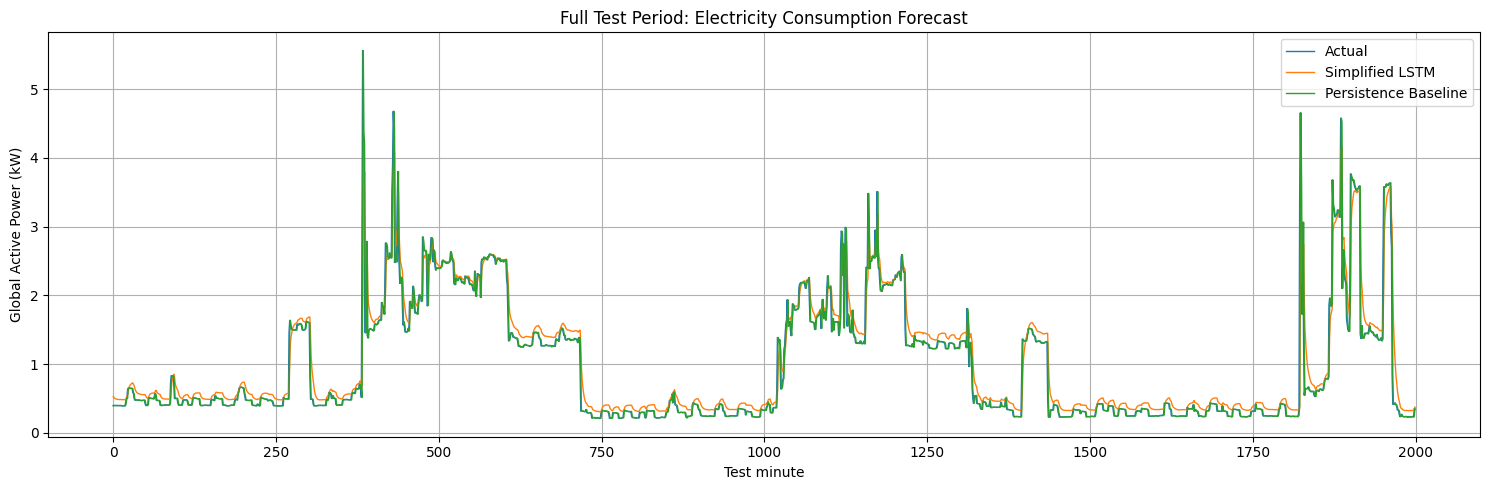

In [25]:

import matplotlib.pyplot as plt

plt.figure(figsize=(15, 5))
plt.plot(actual_kw, label="Actual", linewidth=1)
plt.plot(simple_pred, label="Simplified LSTM", linewidth=1)
plt.plot(simple_baseline, label="Persistence Baseline", linewidth=1)

plt.title("Full Test Period: Electricity Consumption Forecast")
plt.xlabel("Test minute")
plt.ylabel("Global Active Power (kW)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()
